In [ ]:
# -*- coding: utf-8 -*-
"""
This top Code block is the final iteration used to create plots and data for the project/presentation.
Created on Sun Nov 23 12:59:27 2025

@author: logan
"""

import random
import math
import matplotlib.pyplot as plt
import argparse
import pandas as pd

parser=argparse.ArgumentParser()

parser.add_argument('--particles', '-p')
parser.add_argument('--plotted_variable', '-plot')
parser.add_argument('--time', '-t')
parser.add_argument('--save', '-s')
parser.add_argument('--radius', '-r')
parser.add_argument('--Randomizer_seed', '-seed')
parser.add_argument('--weighted', '-w')

args=parser.parse_args()

pi = math.pi
e = math.e

critRad = 1.0
atomVol = 0.01
space = 3
atomMass = 0.01
distMult=1.25

debug = 0
debug2 =0
debug3=0
debug4=0

def eqn(rad):
    formula = e**(-1*(rad-1))
    return formula

def getCritVol(critRad):
    CritVolume = 4/3*pi*(critRad**3)
    return CritVolume

critVol = getCritVol(critRad)


def genGaussList(num, mu=critRad, sigma=1):
    numList = []
    for i in range(num):
        numList.append(random.gauss(mu, sigma))

    return numList

critVolSigma = critVol/4

def makeListLength(inList, finalLength, val=0):
    outList = inList
    while len(outList) != finalLength:
        outList.append(val)
    return outList

def genGaussVol(mu=critVol, sigma=critVolSigma):
    return random.gauss(mu, sigma)

class atom:
    def __init__(self, mass, vol, charge=0):
        self.mass = mass
        self.vol = vol
        self.charge=charge

    def getmass(self):
        return self.mass

    def getvol(self):
        return self.vol

    def getcharge(self):
        return self.charge

    def getradius(self):
        pass


class particle:

    def __init__(self, xPos, yPos, zPos=0,initAtoms=[]):
        self.volData=[]
        self.radData=[]
        self.epsteinlist = initAtoms
        self.x = xPos
        self.y = yPos
        self.z = zPos

    def getepsteinList(self):
        return self.epsteinlist

    def getx(self):
        return self.x

    def gety(self):
        return self.y

    def getz(self):
        return self.z

    def getcoords(self):
        return f'{self.getx()},{self.gety()},{self.getz()}'

    def addem(self, atom):
        self.epsteinlist.append(atom)

    def losem(self, index=0):
        lostAtom = self.epsteinlist.pop(index)
        return lostAtom

    def getVol(self):
        volSum = 0
        atomList = self.getepsteinList()
        for atom in atomList:
            volSum += atom.getvol()
        self.vol = volSum
        return self.vol

    def getrad(self):
        vol=self.getVol()
        if debug2: print(vol)
        radius=(3/4/pi*vol)**(1/3)
        if debug2: print(radius)
        return radius

    def getnumAtoms(self):
        return len(self.getepsteinList())

    def recordData(self):
        self.volData.append(self.getVol())
        self.radData.append(self.getrad())

    def getvolData(self):
        return self.volData

    def getradData(self):
        return self.radData

    def __str__(self):
        return f'Particle with volume of {round(self.getVol(),2)}, radius of {round(self.getrad(),3)}, and atom count of {round(self.getnumAtoms(),2)} at ({round(self.x, 2)},{round(self.y, 2)},{round(self.z, 2)})'

    def __repr__(self):
        return f'Particle with volume of {round(self.getVol(),2)}, radius of {round(self.getrad(),3)}, and atom count of {round(self.getnumAtoms(),2)} at ({round(self.x, 2)},{round(self.y, 2)},{round(self.z, 2)})'

class system:
    def __init__(self, particleList=[], criticalRadius=critRad, sysType='std', dimensions=''):
        self.lostpartList=[]
        self.partList = []
        self.avgRadData=[]
        self.criticalRadius=criticalRadius
        self.dimensions=dimensions
        for particle in list(particleList):
            self.partList.append(particle)

    def recordData(self):
        radSum = 0
        for i in range(len(self.getpartList())):
            radSum+=self.getpartList()[i].getrad()
        avgRad = radSum/len(self.getpartList())
        self.avgRadData.append(avgRad)

    def getavgRadData(self):
        return self.avgRadData

    def copy(self, criticalRadius=critRad, sysType='std'):
        partList = list(self.getpartList())
        dims=str(self.getdimensions())
        newSys = system(partList, criticalRadius, sysType,dims)
        return newSys

    def getpartList(self):
        return self.partList

    def addPart(self, part):
        self.partList.append(part)

    def removefrompartList(self,particle):
        self.partList.remove(particle)

    def buildStdSystem(self, numParts, dimensions='10x10'):
        dimList = dimensions.split('x')
        self.dimList = list(dimList)
        self.numParts = numParts
        for i in range(len(dimList)):
            dimList[i] = int(dimList[i])
        while len(dimList) < space:
            dimList.append(0)

        dimStrList = []
        for i in range(len(dimList)):
            dimStrList.append(str(dimList[i]))

        self.dimensions = 'x'.join(dimStrList)

        gaussList = []

        for i in range(numParts):
            gaussList.append((genGaussVol()*distMult)//atomVol)

        for i in range(int(numParts)):
            randX = random.random()*dimList[0]
            randY = random.random()*dimList[1]
            randZ = random.random()*dimList[2]
            atomList = []

            for j in range(int(gaussList[i])):
                atomList.append(atom(atomMass, atomVol))

            self.addPart(particle(randX, randY, randZ, atomList))
        if debug: print(self.partList)

    def getnumParts(self):
        return len(self.getpartList())

    def getdimensions(self):
        return self.dimensions

    def getdimList(self):
        return self.dimList

    def getlostpartList(self):
        return self.lostpartList

    def getmedianrad(self):
        radList = []
        for i in range(len(self.getpartList())):
            radList.append(self.getpartList()[i].getrad())
        sortedradList = sorted(radList)

        while len(sortedradList)>2:
            sortedradList.pop(0)
            sortedradList.pop(-1)

        if len(sortedradList)==2:
            return (sortedradList[0]+sortedradList[1])/2
        return sortedradList[0]

    def __str__(self):
        partList = self.getpartList()
        prtStr = f'{self.getdimensions()} system with {len(self.getpartList())} particles.\n'
        for particle in partList:
            prtStr += (str(particle) + '\n')

        return prtStr

    def __repr__(self):
        partList = self.getpartList()
        prtStr = f'{self.getdimensions()} system with {len(self.getpartList())} particles.\n'
        for particle in partList:
            prtStr += (str(particle) + '\n')

        return prtStr

    def iterate(self,criticalRadius, weighted=True, prop='rad'):
        lostAtomList =[]
        partList=self.getpartList()
        templostpartList=[]
        for i in range(self.getnumParts()):
            part = partList[i]
            rad = part.getrad()
            if rad < criticalRadius:
                lostAtom=part.losem()
                lostAtomList.append(lostAtom)
            else:
                randNum = random.random()
                threshold = eqn(rad/criticalRadius)
                if randNum < threshold:
                    lostAtom=part.losem()
                    lostAtomList.append(lostAtom)
            self.recordData()

            part.recordData()

            if part.getnumAtoms() <=0:
                self.lostpartList.append(part)
                templostpartList.append(part)
            #part.recordData()

        for i in range(len(templostpartList)):
            self.removefrompartList(templostpartList[i])

        #Here is where the algorithm selects a particle to receive the lost atom

        if weighted==False:

            for i in range(len(lostAtomList)):
                randIndex=random.randint(0, self.getnumParts()-1)
                self.partList[randIndex].addem(lostAtomList[i])
        else:
            for i in range(len(lostAtomList)):
                weightedIndex=self.getWeightedIndex(prop)
                self.partList[weightedIndex].addem(lostAtomList[i])

    #IterateNtimes is what plots the function as an option

    def getWeightedIndex(self, prop='rad'):


        if prop=='avgRad':
            prop ='rad'

        partList = self.getpartList()
        volSum = 0
        if prop=='rad':
            for i in range(len(partList)):
                volSum+= partList[i].getrad()**2
        if debug4: print(f'volSum {volSum}')
        weightedVal=random.uniform(0, volSum)
        if debug4: print(f'weightedVal {weightedVal}')
        checkSum = 0
        if prop=='rad':
            for i in range(len(partList)):
                checkSum += partList[i].getrad()**2
                if debug4:print(f'checkSum {checkSum}')
                if weightedVal<= checkSum:
                    weightedIndex=i
                    if debug4: print(f'Returned {i}')
                    return weightedIndex


    def iterateNtimes(self,N,rad=critRad, plot='rad',prt=True,save=False, weighted=True):
        xSpace=[]
        critLine=[]
        for i in range(N):
            self.iterate(rad, weighted, plot)
            xSpace.append(i)
            if prt: print(f'{round((i+1)/N*100,2)}% complete')
            critLine.append(rad)

        initParts=int(self.getnumParts())

        combinedList = self.getpartList()+self.getlostpartList()

        if plot=='vol':

            for i in range(len(combinedList)):
                tempxSpace = xSpace[:len(combinedList[i].getvolData())]
                plt.plot(tempxSpace, combinedList[i].getvolData())
            plt.plot(xSpace,critLine)
            plt.title(f'Particle Radius vs. Time {len(combinedList)}-Particle Plot')
            if save:
                plt.savefig(f'CritRad_{rad}_{N}N_{len(combinedList)}_Particles_titled_weighted{weighted}.{save}')
                plt.show()

        if plot=='rad':

            for i in range(len(combinedList)):
                tempxSpace = xSpace[:len(combinedList[i].getradData())]
                plt.plot(tempxSpace, combinedList[i].getradData())
            plt.plot(xSpace,critLine)
            plt.title(f'Particle Radius vs. Time {len(combinedList)}-Particle Plot')
            if save:
                plt.savefig(f'CritRad_{rad}_{N}N_{len(combinedList)}_Particles_titled_weighted{weighted}.{save}')
                plt.show()

        if plot=='avgRad':
            avgRadData=self.getavgRadData()
            xSpace=[i for i in range(len(avgRadData))]
            plt.plot(xSpace,avgRadData)
            plt.title(f'Average Particle Radius vs. Time {len(combinedList)}-Particle Plot')
            if save:
                plt.savefig(f'CritRad_{rad}_{N}N_{len(combinedList)}_Particles_titled_weighted{weighted}_avgRad.{save}')

    def makecsv(self, N,rad=critRad, plot='rad',prt=True,save=False):
        partList = self.getpartList()+self.getlostpartList()
        timeList = [i for i in range(N)]
        dataLists = [timeList]
        dataTitleList = ['Time']
        for i in range(len(partList)):
            tempRadList = makeListLength(partList[i].getradData(), N)
            dataLists.append(tempRadList)
            dataTitleList.append(f'Particle {i+1} Radius')

        for i in range(len(partList)):
            cord = partList[i].getcoords()
            tempCoords = [cord for i in range(N)]
            dataLists.append(tempCoords)
            dataTitleList.append(f'Particle {i+1} Position')

        #titleAndDataListCombined = [dataTitleList, dataLists]

        dataDict = {dataTitleList[i]: dataLists[i] for i in range(len(dataTitleList))}

        df = pd.DataFrame(dataDict)

        df.to_csv(f'CritRad_{rad}_{it}N_{parts}_Particles_weighted{weighted}.csv', index=False)


def run1():
    print(f'Critical radius is: {critRad}')
    print(f'Critical volume is: {critVol}')

def run2():
    sys = system()
    sys.buildStdSystem(10)
    print(sys)
    sys.iterate()
    print(sys)

def run3(parts, N,rad=critRad, plot='rad',prt=True,save=True,weighted=True):
    sys = system()
    sys.buildStdSystem(parts)

    initData = []

    for i in range(parts):
        initData.append(f'Particle {i} with radius of {sys.getpartList()[i].getrad()}')

    initDataText = '\n'.join(initData)

    sys.iterateNtimes(N,rad, plot,prt,save,weighted)
    sys.makecsv(N, rad, plot, prt, save)

    print(f'Completed run with following parameters:\n{parts} Particles\nseed={seeded}\nt={it}\nCritical Radius of {rad}\nPlotting {plotted_variable}\nSaved to a {save} file\n    Saving Summary to CritRad_{rad}_{it}N_{parts}_Particles_{weightedText}_{plotted_variable}plot.txt\n')
    with open(f'CritRad_{rad}_{it}N_{parts}_Particles_{weightedText}_{plotted_variable}plot.txt', 'w') as f:
        f.write(f'Completed run with following parameters:\n{parts} Particles\nseed={seeded}\nt={it}\nCritical Radius of {rad}\nPlotting {plotted_variable}\nSaved to a {save} file\n    Saved Summary to CritRad_{rad}_{it}N_{parts}_Particles_{weightedText}_{plotted_variable}plot.txt\n{initDataText}')

    print('Summary Saved.')

def run4():
    sys= system()
    sys.buildStdSystem(30)
    print(sys)

def run5(iterations):
    radList = [1.0,1.5]
    sys =  system()
    sys.buildStdSystem(10)
    sys.iterateWparams(it,radList)

def run6(parts, N,rad=critRad, plot='rad',prt=True,save=True,weighted=True):
    sys=system()
    sys.buildStdSystem(parts)
    sys.iterate(rad,weighted, plot)

def run7(parts, N,rad=critRad, plot='rad',prt=True,save=True,weighted=True):
    sys=system()
    sys.buildStdSystem(parts)
    print(sys.getmedianrad())

    #Here is where the actual implementation is. This version works with either command line or just normally running.
    #Just find the parameter you want to change and then change it.
    #The output txt, csv, and plot file should all have the same name so things don't get confusing.
    #Coordinates in the csv file are done in the form 'x,y,z' so they should be easy to access individually with a .split(',') function
    #Right now the only thing the csv file outputs is radius, time, and position but I feel that is all we need for the visualization.


if __name__ == '__main__':
    if args.particles:
        parts = args.particles
    else:
        parts=15
    if args.Randomizer_seed:
        random.seed(args.Randomizer_seed)
        seeded=args.Randomizer_seed
    else:
        random.seed(67)
        seeded='67'
    if args.time:
        it=args.time
    else:
        it = 20000
    if args.radius:
        rad = args.radius
    else:
        rad = 1.09
    if args.plotted_variable:
        if args.plotted_variable=='rad' or args.plotted_variable=='vol':
            plotted_variable=args.plotted_variable
        elif args.plotted_variable=='radius':
            plotted_variable='rad'
        elif args.plotted_variable=='volume':
            plotted_variable='vol'
        else:
            plotted_variable='rad'
    else:
        plotted_variable='rad'
    if args.save:
        save=args.save
    else:
        save='png'

    if args.weighted:
        weighted = args.weighted
        weightedText=f'weighted{weighted}'
    else:
        weighted=False
        weightedText=f'weighted{weighted}'
    printProgress=True

    critRad = rad

    #run1()
    run3(parts,it,rad,plotted_variable,printProgress,save,weighted)

In [ ]:
# -*- coding: utf-8 -*-
"""
Created on Sun Nov 23 12:59:27 2025

@author: logan
"""

import random
import math
import matplotlib.pyplot as plt
import argparse
import pandas as pd

parser=argparse.ArgumentParser()

parser.add_argument('--particles', '-p')
parser.add_argument('--plotted_variable', '-plot')
parser.add_argument('--time', '-t')
parser.add_argument('--save', '-s')
parser.add_argument('--radius', '-r')
parser.add_argument('--Randomizer_seed', '-seed')

args=parser.parse_args()

pi = math.pi
e = math.e

critRad = 1.00
atomVol = 0.01
space = 3
atomMass = 0.01
distMult=1.25

debug = 0
debug2 =0
debug3=0

def eqn(rad):
    formula = e**(-1*(rad-1))
    return formula

def getCritVol(critRad):
    CritVolume = 4/3*pi*(critRad**3)
    return CritVolume

critVol = getCritVol(critRad)


def genGaussList(num, mu=critRad, sigma=1):
    numList = []
    for i in range(num):
        numList.append(random.gauss(mu, sigma))

    return numList

critVolSigma = critVol/4

def makeListLength(inList, finalLength, val=0):
    outList = inList
    while len(outList) != finalLength:
        outList.append(val)
    return outList

def genGaussVol(mu=critVol, sigma=critVolSigma):
    return random.gauss(mu, sigma)

class atom:
    def __init__(self, mass, vol, charge=0):
        self.mass = mass
        self.vol = vol
        self.charge=charge

    def getmass(self):
        return self.mass

    def getvol(self):
        return self.vol

    def getcharge(self):
        return self.charge

    def getradius(self):
        pass


class particle:

    def __init__(self, xPos, yPos, zPos=0,initAtoms=[]):
        self.volData=[]
        self.radData=[]
        self.epsteinlist = initAtoms
        self.x = xPos
        self.y = yPos
        self.z = zPos

    def getepsteinList(self):
        return self.epsteinlist

    def getx(self):
        return self.x

    def gety(self):
        return self.y

    def getz(self):
        return self.z

    def getcoords(self):
        return f'{self.getx()},{self.gety()},{self.getz()}'

    def addem(self, atom):
        self.epsteinlist.append(atom)

    def losem(self, index=0):
        lostAtom = self.epsteinlist.pop(index)
        return lostAtom

    def getVol(self):
        volSum = 0
        atomList = self.getepsteinList()
        for atom in atomList:
            volSum += atom.getvol()
        self.vol = volSum
        return self.vol

    def getrad(self):
        vol=self.getVol()
        if debug2: print(vol)
        radius=(3/4/pi*vol)**(1/3)
        if debug2: print(radius)
        return radius

    def getnumAtoms(self):
        return len(self.getepsteinList())

    def recordData(self):
        self.volData.append(self.getVol())
        self.radData.append(self.getrad())

    def getvolData(self):
        return self.volData

    def getradData(self):
        return self.radData

    def __str__(self):
        return f'Particle with volume of {round(self.getVol(),2)}, radius of {round(self.getrad(),3)}, and atom count of {round(self.getnumAtoms(),2)} at ({round(self.x, 2)},{round(self.y, 2)},{round(self.z, 2)})'

    def __repr__(self):
        return f'Particle with volume of {round(self.getVol(),2)}, radius of {round(self.getrad(),3)}, and atom count of {round(self.getnumAtoms(),2)} at ({round(self.x, 2)},{round(self.y, 2)},{round(self.z, 2)})'

class system:
    def __init__(self, particleList=[], criticalRadius=critRad, sysType='std', dimensions=''):
        self.lostpartList=[]
        self.partList = []
        self.criticalRadius=criticalRadius
        self.dimensions=dimensions
        for particle in list(particleList):
            self.partList.append(particle)

    def copy(self, criticalRadius=critRad, sysType='std'):
        partList = list(self.getpartList())
        dims=str(self.getdimensions())
        newSys = system(partList, criticalRadius, sysType,dims)
        return newSys

    def getpartList(self):
        return self.partList

    def addPart(self, part):
        self.partList.append(part)

    def removefrompartList(self,particle):
        self.partList.remove(particle)

    def buildStdSystem(self, numParts, dimensions='10x10'):
        dimList = dimensions.split('x')
        self.dimList = list(dimList)
        self.numParts = numParts
        for i in range(len(dimList)):
            dimList[i] = int(dimList[i])
        while len(dimList) < space:
            dimList.append(0)

        dimStrList = []
        for i in range(len(dimList)):
            dimStrList.append(str(dimList[i]))

        self.dimensions = 'x'.join(dimStrList)

        gaussList = []

        for i in range(numParts):
            gaussList.append((genGaussVol()*distMult)//atomVol)

        for i in range(int(numParts)):
            randX = random.random()*dimList[0]
            randY = random.random()*dimList[1]
            randZ = random.random()*dimList[2]
            atomList = []

            for j in range(int(gaussList[i])):
                atomList.append(atom(atomMass, atomVol))

            self.addPart(particle(randX, randY, randZ, atomList))
        if debug: print(self.partList)

    def getnumParts(self):
        return len(self.getpartList())

    def getdimensions(self):
        return self.dimensions

    def getdimList(self):
        return self.dimList

    def getlostpartList(self):
        return self.lostpartList

    def __str__(self):
        partList = self.getpartList()
        prtStr = f'{self.getdimensions()} system with {len(self.getpartList())} particles.\n'
        for particle in partList:
            prtStr += (str(particle) + '\n')

        return prtStr

    def __repr__(self):
        partList = self.getpartList()
        prtStr = f'{self.getdimensions()} system with {len(self.getpartList())} particles.\n'
        for particle in partList:
            prtStr += (str(particle) + '\n')

        return prtStr

    def iterate(self,criticalRadius):
        lostAtomList =[]
        partList=self.getpartList()
        templostpartList=[]
        for i in range(self.getnumParts()):
            part = partList[i]
            rad = part.getrad()
            if rad < criticalRadius:
                lostAtom=part.losem()
                lostAtomList.append(lostAtom)
            else:
                randNum = random.random()
                threshold = eqn(rad/criticalRadius)
                if randNum < threshold:
                    lostAtom=part.losem()
                    lostAtomList.append(lostAtom)

            part.recordData()

            if part.getnumAtoms() <=0:
                self.lostpartList.append(part)
                templostpartList.append(part)
            #part.recordData()

        for i in range(len(templostpartList)):
            self.removefrompartList(templostpartList[i])

        for i in range(len(lostAtomList)):
            randIndex=random.randint(0, self.getnumParts()-1)
            self.partList[randIndex].addem(lostAtomList[i])

    def iterateNtimes(self,N,rad=critRad, plot='rad',prt=True,save=False):
        xSpace=[]
        critLine=[]
        for i in range(N):
            self.iterate(rad)
            xSpace.append(i)
            if prt: print(f'{round((i+1)/N*100,2)}% complete')
            critLine.append(rad)

        initParts=int(self.getnumParts())

        if plot=='vol':
            combinedList = self.getpartList()+self.getlostpartList()
            for i in range(len(combinedList)):
                tempxSpace = xSpace[:len(combinedList[i].getvolData())]
                plt.plot(tempxSpace, combinedList[i].getvolData())
            plt.plot(xSpace,critLine)
            plt.title(f'Particle Radius vs. Time {len(combinedList)}-Particle Plot')
            if save:
                plt.savefig(f'CritRad_{rad}_{N}N_{len(combinedList)}_Particles_titled.{save}')
                plt.show()

        if plot=='rad':
            combinedList = self.getpartList()+self.getlostpartList()
            for i in range(len(combinedList)):
                tempxSpace = xSpace[:len(combinedList[i].getradData())]
                plt.plot(tempxSpace, combinedList[i].getradData())
            plt.plot(xSpace,critLine)
            plt.title(f'Particle Radius vs. Time {len(combinedList)}-Particle Plot')
            if save:
                plt.savefig(f'CritRad_{rad}_{N}N_{len(combinedList)}_Particles_titled.{save}')
                plt.show()

    def makecsv(self, N,rad=critRad, plot='rad',prt=True,save=False):
        partList = self.getpartList()+self.getlostpartList()
        timeList = [i for i in range(N)]
        dataLists = [timeList]
        dataTitleList = ['Time']
        for i in range(len(partList)):
            tempRadList = makeListLength(partList[i].getradData(), N)
            dataLists.append(tempRadList)
            dataTitleList.append(f'Particle {i+1} Radius')

        for i in range(len(partList)):
            cord = partList[i].getcoords()
            tempCoords = [cord for i in range(N)]
            dataLists.append(tempCoords)
            dataTitleList.append(f'Particle {i+1} Position')

        #titleAndDataListCombined = [dataTitleList, dataLists]

        dataDict = {dataTitleList[i]: dataLists[i] for i in range(len(dataTitleList))}

        df = pd.DataFrame(dataDict)

        df.to_csv(f'CritRad_{rad}_{it}N_{parts}_Particles.csv', index=False)


def run1():
    print(f'Critical radius is: {critRad}')
    print(f'Critical volume is: {critVol}')

def run2():
    sys = system()
    sys.buildStdSystem(10)
    print(sys)
    sys.iterate()
    print(sys)

def run3(parts, N,rad=critRad, plot='rad',prt=True,save=True):
    sys = system()
    sys.buildStdSystem(parts)
    sys.iterateNtimes(N,rad, plot,prt,save)
    sys.makecsv(N, rad, plot, prt, save)

def run4():
    sys= system()
    sys.buildStdSystem(30)
    print(sys)

def run5(iterations):
    radList = [1.0,1.5]
    sys =  system()
    sys.buildStdSystem(10)
    sys.iterateWparams(it,radList)

    #Here is where the actual implementation is. This version works with either command line or just normally running.
    #Just find the parameter you want to change and then change it.
    #The output txt, csv, and plot file should all have the same name so things don't get confusing.
    #Coordinates in the csv file are done in the form 'x,y,z' so they should be easy to access individually with a .split(',') function
    #Right now the only thing the csv file outputs is radius, time, and position but I feel that is all we need for the visualization.


if __name__ == '__main__':
    if args.particles:
        parts = args.particles
    else:
        parts=15
    if args.Randomizer_seed:
        random.seed(args.Randomizer_seed)
        seeded=args.Randomizer_seed
    else:
        seeded='unseeded'
    if args.time:
        it=args.time
    else:
        it = 10000
    if args.radius:
        rad = args.radius
    else:
        rad = 1.0
    if args.plotted_variable:
        if args.plotted_variable=='rad' or args.plotted_variable=='vol':
            plotted_variable=args.plotted_variable
        elif args.plotted_variable=='radius':
            plotted_variable='rad'
        elif args.plotted_variable=='volume':
            plotted_variable='vol'
        else:
            plotted_variable='rad'
    else:
        plotted_variable='rad'
    if args.save:
        save=args.save
    else:
        save='png'
    #run1()
    run3(parts,it,rad,plotted_variable,False,save)
    print(f'Completed run with following parameters:\n{parts} Particles\nseed={seeded}\nt={it}\nCritical Radius of {rad}\nPlotting {plotted_variable}\nSaved to a {save} file\n    Saving Summary to CritRad_{rad}_{it}N_{parts}_Particles.txt\n')
    with open(f'CritRad_{rad}_{it}N_{parts}_Particles.txt', 'w') as f:
        f.write(f'Completed run with following parameters:\n{parts} Particles\nseed={seeded}\nt={it}\nCritical Radius of {rad}\nPlotting {plotted_variable}\nSaved to a {save} file\n    Saved Summary to CritRad_{rad}_{it}N_{parts}_Particles.txt\n')
    print('Summary Saved.')

usage: colab_kernel_launcher.py [-h] [--particles PARTICLES]
                                [--plotted_variable PLOTTED_VARIABLE]
                                [--time TIME] [--save SAVE] [--radius RADIUS]
                                [--Randomizer_seed RANDOMIZER_SEED]
colab_kernel_launcher.py: error: unrecognized arguments: -f /root/.local/share/jupyter/runtime/kernel-7a84e58b-da90-4a32-a212-834cf86c522f.json


SystemExit: 2

/usr/local/lib/python3.12/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


Streaming output truncated to the last 5000 lines.
50.01% complete
50.02% complete
50.03% complete
50.04% complete
50.05% complete
50.06% complete
50.07% complete
50.08% complete
50.09% complete
50.1% complete
50.11% complete
50.12% complete
50.13% complete
50.14% complete
50.15% complete
50.16% complete
50.17% complete
50.18% complete
50.19% complete
50.2% complete
50.21% complete
50.22% complete
50.23% complete
50.24% complete
50.25% complete
50.26% complete
50.27% complete
50.28% complete
50.29% complete
50.3% complete
50.31% complete
50.32% complete
50.33% complete
50.34% complete
50.35% complete
50.36% complete
50.37% complete
50.38% complete
50.39% complete
50.4% complete
50.41% complete
50.42% complete
50.43% complete
50.44% complete
50.45% complete
50.46% complete
50.47% complete
50.48% complete
50.49% complete
50.5% complete
50.51% complete
50.52% complete
50.53% complete
50.54% complete
50.55% complete
50.56% complete
50.57% complete
50.58% complete
50.59% complete
50.6% comp

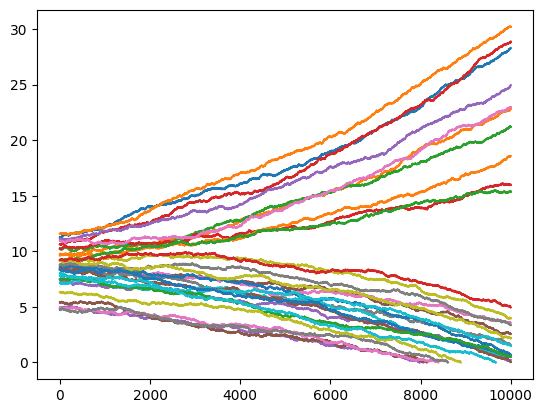

In [ ]:
# -*- coding: utf-8 -*-
"""
Created on Sun Nov 23 12:59:27 2025

@author: logan
"""

import random
import math
import copy
import matplotlib.pyplot as plt

pi = math.pi
e = math.e

critRad = 1.25
atomVol = 0.01
space = 3
atomMass = 0.01

debug = 0
debug2 =0

def eqn(rad):
    formula = e**(-1*(rad-1))
    return formula

def getCritVol(critRad):
    CritVolume = 4/3*pi*(critRad**3)
    return CritVolume

critVol = getCritVol(critRad)


def genGaussList(num, mu=critRad, sigma=1):
    numList = []
    for i in range(num):
        numList.append(random.gauss(mu, sigma))

    return numList

critVolSigma = critVol/4

def genGaussVol(mu=critVol, sigma=critVolSigma):
    return random.gauss(mu, sigma)

class atom:
    def __init__(self, mass, vol, charge=0):
        self.mass = mass
        self.vol = vol
        self.charge=charge

    def getmass(self):
        return self.mass

    def getvol(self):
        return self.vol

    def getcharge(self):
        return self.charge

    def getradius(self):
        pass


class particle:

    def __init__(self, xPos, yPos, zPos=0,initAtoms=[]):
        self.volData=[]
        self.epsteinlist = initAtoms
        self.x = xPos
        self.y = yPos
        self.z = zPos

    def getepsteinList(self):
        return self.epsteinlist

    def addem(self, atom):
        self.epsteinlist.append(atom)

    def losem(self, index=0):
        lostAtom = self.epsteinlist.pop(index)
        return lostAtom

    def getVol(self):
        volSum = 0
        atomList = self.getepsteinList()
        for atom in atomList:
            volSum += atom.getvol()
        self.vol = volSum
        return self.vol

    def getrad(self):
        vol=self.getVol()
        if debug2: print(vol)
        radius=(3/4/pi*vol)**(1/3)
        if debug2: print(radius)
        return radius

    def getnumAtoms(self):
        return len(self.getepsteinList())

    def recordData(self):
        self.volData.append(self.getVol())

    def getvolData(self):
        return self.volData

    def __str__(self):
        return f'Particle with volume of {round(self.getVol(),2)}, radius of {round(self.getrad(),3)}, and atom count of {round(self.getnumAtoms(),2)} at ({round(self.x, 2)},{round(self.y, 2)},{round(self.z, 2)})'

    def __repr__(self):
        return f'Particle with volume of {round(self.getVol(),2)}, radius of {round(self.getrad(),3)}, and atom count of {round(self.getnumAtoms(),2)} at ({round(self.x, 2)},{round(self.y, 2)},{round(self.z, 2)})'

class system:
    def __init__(self, *particles, sysType='std', critRad=critRad):
        self.lostpartList=[]
        self.partList = []
        for particle in particles:
            self.partList.append(particle)


    def getpartList(self):
        return self.partList

    def addPart(self, part):
        self.partList.append(part)

    def removefrompartList(self,particle):
        self.partList.remove(particle)

    def buildStdSystem(self, numParts, dimensions='10x10'):
        dimList = dimensions.split('x')
        self.dimList = list(dimList)
        self.numParts = numParts
        for i in range(len(dimList)):
            dimList[i] = int(dimList[i])
        while len(dimList) < space:
            dimList.append(0)

        dimStrList = []
        for i in range(len(dimList)):
            dimStrList.append(str(dimList[i]))

        self.dimensions = 'x'.join(dimStrList)

        gaussList = []

        for i in range(numParts):
            gaussList.append(genGaussVol()//atomVol)

        for i in range(int(numParts)):
            randX = random.random()*dimList[0]
            randY = random.random()*dimList[1]
            randZ = random.random()*dimList[2]
            atomList = []

            for j in range(int(gaussList[i])):
                atomList.append(atom(atomMass, atomVol))

            self.addPart(particle(randX, randY, randZ, atomList))
        if debug: print(self.partList)

    def getnumParts(self):
        return len(self.getpartList())

    def getdimensions(self):
        return self.dimensions

    def getdimList(self):
        return self.dimList

    def getlostpartList(self):
        return self.lostpartList

    def __str__(self):
        partList = self.getpartList()
        prtStr = f'{self.getdimensions()} system with {len(self.getpartList())} particles.\n'
        for i in range(len(partList)):
            prtStr += (str(partList[i]) + '\n')

        return prtStr

    def __repr__(self):
        partList = self.getpartList()
        prtStr = f'{self.getdimensions()} system with {len(self.getpartList())} particles.\n'
        for particle in partList:
            prtStr += (str(particle) + '\n')

        return prtStr

    def iterate(self):
        lostAtomList =[]
        partList=self.getpartList()
        templostpartList=[]
        for i in range(self.getnumParts()):
            part = partList[i]
            rad = part.getrad()
            if rad < critRad:
                lostAtom=part.losem()
                lostAtomList.append(lostAtom)
            else:
                randNum = random.random()
                threshold = eqn(rad/critRad)
                if randNum < threshold:
                    lostAtom=part.losem()
                    lostAtomList.append(lostAtom)

            part.recordData()

            if part.getnumAtoms() <=0:
                self.lostpartList.append(part)
                templostpartList.append(part)
            #part.recordData()

        for i in range(len(templostpartList)):
            self.removefrompartList(templostpartList[i])

        #Here is where the algorithm selects a particle to receive the lost atom

        for i in range(len(lostAtomList)):
            randIndex=random.randint(0, self.getnumParts()-1)
            self.partList[randIndex].addem(lostAtomList[i])

    #IterateNtimes is what plots the function as an option

    def iterateNtimes(self,N,plot=True):
        xSpace=[]
        for i in range(N):
            self.iterate()
            xSpace.append(i)
            print(f'{round((i+1)/N*100,2)}% complete')

        if plot:
            combinedList = self.getpartList()+self.getlostpartList()
            for i in range(len(combinedList)):
                tempxSpace = xSpace[:len(combinedList[i].getvolData())]
                plt.plot(tempxSpace, combinedList[i].getvolData())

def run1():
    print(f'Critical radius is: {critRad}')
    print(f'Critical volume is: {critVol}')

def run2():
    sys = system()
    sys.buildStdSystem(10)
    print(sys)
    sys.iterate()
    print(sys)

def run3():
    sys = system()
    sys.buildStdSystem(30)
    sys.iterateNtimes(10000)

def run4():
    sys= system()
    sys.buildStdSystem(30)
    print(sys)

if __name__ == '__main__':
    random.seed(67)
    run1()
    run3()

In [ ]:
# -*- coding: utf-8 -*-
"""
Created on Sun Nov 23 12:59:27 2025

@author: logan
"""

import random
import math
import matplotlib.pyplot as plt
import argparse

parser=argparse.ArgumentParser()

#--particles: number of particles in simulation
#--plotted_variale: can choose whether 'vol' (volume) or 'rad' (radius) is plotted against timestep
#--time: the amount of timesteps the simulation operates for. Usually somewhere around 10,000-60,000 depending on initial particle size.
#--save: chooses file type to save to 'png' 'pdf' etc.
#--radius: chooses the critical radius to simulate
#--Randomizer_seed: optional argument (all are optional but this is more) which provides a seed for random module
#If you want a progress bar, change the False inside the run3() command to True

parser.add_argument('--particles', '-p')
parser.add_argument('--plotted_variable', '-plot')
parser.add_argument('--time', '-t')
parser.add_argument('--save', '-s')
parser.add_argument('--radius', '-r')
parser.add_argument('--Randomizer_seed', '-seed')

args=parser.parse_args([])

pi = math.pi
e = math.e

#critRad is mostly for testing purposes, no need to change it --radius does it for you.
critRad = 1.00
atomVol = 0.01
space = 3
atomMass = 0.01

#distMult is a multiplier I add to the gaussian distribution to get data that looks good
#It's not really necessary, but everything below critical radius goes to zero pretty much
#instantly so this means there are more values above it
distMult=1.25

debug = 0
debug2 =0
debug3=0

def eqn(rad):
    formula = e**(-1*(rad-1))
    return formula

def getCritVol(critRad):
    CritVolume = 4/3*pi*(critRad**3)
    return CritVolume

critVol = getCritVol(critRad)


def genGaussList(num, mu=critRad, sigma=1):
    numList = []
    for i in range(num):
        numList.append(random.gauss(mu, sigma))

    return numList

critVolSigma = critVol/4

def genGaussVol(mu=critVol, sigma=critVolSigma):
    return random.gauss(mu, sigma)

class atom:
    def __init__(self, mass, vol, charge=0):
        self.mass = mass
        self.vol = vol
        self.charge=charge

    def getmass(self):
        return self.mass

    def getvol(self):
        return self.vol

    def getcharge(self):
        return self.charge

    def getradius(self):
        pass


class particle:

    def __init__(self, xPos, yPos, zPos=0,initAtoms=[]):
        self.volData=[]
        self.radData=[]
        self.epsteinlist = initAtoms
        self.x = xPos
        self.y = yPos
        self.z = zPos

    def getepsteinList(self):
        return self.epsteinlist

    def addem(self, atom):
        self.epsteinlist.append(atom)

    def losem(self, index=0):
        lostAtom = self.epsteinlist.pop(index)
        return lostAtom

    def getVol(self):
        volSum = 0
        atomList = self.getepsteinList()
        for atom in atomList:
            volSum += atom.getvol()
        self.vol = volSum
        return self.vol

    def getrad(self):
        vol=self.getVol()
        if debug2: print(vol)
        radius=(3/4/pi*vol)**(1/3)
        if debug2: print(radius)
        return radius

    def getnumAtoms(self):
        return len(self.getepsteinList())

    def recordData(self):
        self.volData.append(self.getVol())
        self.radData.append(self.getrad())

    def getvolData(self):
        return self.volData

    def getradData(self):
        return self.radData

    def __str__(self):
        return f'Particle with volume of {round(self.getVol(),2)}, radius of {round(self.getrad(),3)}, and atom count of {round(self.getnumAtoms(),2)} at ({round(self.x, 2)},{round(self.y, 2)},{round(self.z, 2)})'

    def __repr__(self):
        return f'Particle with volume of {round(self.getVol(),2)}, radius of {round(self.getrad(),3)}, and atom count of {round(self.getnumAtoms(),2)} at ({round(self.x, 2)},{round(self.y, 2)},{round(self.z, 2)})'

class system:
    def __init__(self, particleList=[], criticalRadius=critRad, sysType='std', dimensions=''):
        self.lostpartList=[]
        self.partList = []
        self.criticalRadius=criticalRadius
        self.dimensions=dimensions
        for particle in list(particleList):
            self.partList.append(particle)

    def copy(self, criticalRadius=critRad, sysType='std'):
        partList = list(self.getpartList())
        dims=str(self.getdimensions())
        newSys = system(partList, criticalRadius, sysType,dims)
        return newSys

    def getpartList(self):
        return self.partList

    def addPart(self, part):
        self.partList.append(part)

    def removefrompartList(self,particle):
        self.partList.remove(particle)

    def buildStdSystem(self, numParts, dimensions='10x10'):
        dimList = dimensions.split('x')
        self.dimList = list(dimList)
        self.numParts = numParts
        for i in range(len(dimList)):
            dimList[i] = int(dimList[i])
        while len(dimList) < space:
            dimList.append(0)

        dimStrList = []
        for i in range(len(dimList)):
            dimStrList.append(str(dimList[i]))

        self.dimensions = 'x'.join(dimStrList)

        gaussList = []

        for i in range(numParts):
            gaussList.append((genGaussVol()*distMult)//atomVol)

        for i in range(int(numParts)):
            randX = random.random()*dimList[0]
            randY = random.random()*dimList[1]
            randZ = random.random()*dimList[2]
            atomList = []

            for j in range(int(gaussList[i])):
                atomList.append(atom(atomMass, atomVol))

            self.addPart(particle(randX, randY, randZ, atomList))
        if debug: print(self.partList)

    def getnumParts(self):
        return len(self.getpartList())

    def getdimensions(self):
        return self.dimensions

    def getdimList(self):
        return self.dimList

    def getlostpartList(self):
        return self.lostpartList

    def __str__(self):
        partList = self.getpartList()
        prtStr = f'{self.getdimensions()} system with {len(self.getpartList())} particles.\n'
        for particle in partList:
            prtStr += (str(particle) + '\n')

        return prtStr

    def __repr__(self):
        partList = self.getpartList()
        prtStr = f'{self.getdimensions()} system with {len(self.getpartList())} particles.\n'
        for particle in partList:
            prtStr += (str(particle) + '\n')

        return prtStr

    def iterate(self,criticalRadius):
        lostAtomList =[]
        partList=self.getpartList()
        templostpartList=[]
        for i in range(self.getnumParts()):
            part = partList[i]
            rad = part.getrad()
            if rad < criticalRadius:
                lostAtom=part.losem()
                lostAtomList.append(lostAtom)
            else:
                randNum = random.random()
                threshold = eqn(rad/criticalRadius)
                if randNum < threshold:
                    lostAtom=part.losem()
                    lostAtomList.append(lostAtom)

            part.recordData()

            if part.getnumAtoms() <=0:
                self.lostpartList.append(part)
                templostpartList.append(part)
            #part.recordData()

        for i in range(len(templostpartList)):
            self.removefrompartList(templostpartList[i])

        for i in range(len(lostAtomList)):
            randIndex=random.randint(0, self.getnumParts()-1)
            self.partList[randIndex].addem(lostAtomList[i])

    def iterateNtimes(self,N,rad=critRad, plot='rad',prt=True,save=False):
        xSpace=[]
        critLine=[]
        for i in range(N):
            self.iterate(rad)
            xSpace.append(i)
            if prt: print(f'{round((i+1)/N*100,2)}% complete')
            critLine.append(rad)

        initParts=int(self.getnumParts())

        if plot=='vol':
            combinedList = self.getpartList()+self.getlostpartList()
            for i in range(len(combinedList)):
                tempxSpace = xSpace[:len(combinedList[i].getvolData())]
                plt.plot(tempxSpace, combinedList[i].getvolData())
            plt.plot(xSpace,critLine)
            plt.title(f'Particle Radius vs. Time {len(combinedList)}-Particle Plot')
            if save:
                plt.savefig(f'CritRad_{rad}_{N}N_{len(combinedList)}_Particles_titled.{save}')
                plt.close()

        if plot=='rad':
            combinedList = self.getpartList()+self.getlostpartList()
            for i in range(len(combinedList)):
                tempxSpace = xSpace[:len(combinedList[i].getradData())]
                plt.plot(tempxSpace, combinedList[i].getradData())
            plt.plot(xSpace,critLine)
            plt.title(f'Particle Radius vs. Time {len(combinedList)}-Particle Plot')
            if save:
                plt.savefig(f'CritRad_{rad}_{N}N_{len(combinedList)}_Particles_titled.{save}')
                plt.close()



def run1():
    print(f'Critical radius is: {critRad}')
    print(f'Critical volume is: {critVol}')

def run2():
    sys = system()
    sys.buildStdSystem(10)
    print(sys)
    sys.iterate()
    print(sys)

def run3(parts, N,rad=critRad, plot='rad',prt=True,save=True):
    sys = system()
    sys.buildStdSystem(parts)
    sys.iterateNtimes(N,rad, plot,prt,save)

def run4():
    sys= system()
    sys.buildStdSystem(30)
    print(sys)

def run5(iterations):
    radList = [1.0,1.5]
    sys =  system()
    sys.buildStdSystem(10)
    sys.iterateWparams(it,radList)


if __name__ == '__main__':
    if args.particles:
        parts = args.particles
    else:
        parts=15
    if args.Randomizer_seed:
        random.seed(args.Randomizer_seed)
        seeded=args.Randomizer_seed
    else:
        seeded='unseeded'
    if args.time:
        it=args.time
    else:
        it = 10000
    if args.radius:
        rad = args.radius
    else:
        rad = 1.0
    if args.plotted_variable:
        if args.plotted_variable=='rad' or args.plotted_variable=='vol':
            plotted_variable=args.plotted_variable
        elif args.plotted_variable=='radius':
            plotted_variable='rad'
        elif args.plotted_variable=='volume':
            plotted_variable='vol'
        else:
            plotted_variable='rad'
    else:
        plotted_variable='rad'
    if args.save:
        save=args.save
    else:
        save='png'
    #run1()
    run3(parts,it,rad,plotted_variable,False,save)
    print(f'Completed run with following parameters:\n{parts} Particles\nseed={seeded}\nt={it}\nCritical Radius of {rad}\nPlotting {plotted_variable}\nSaved to a {save} file\n    Saving Summary to CritRad_{rad}_{it}N_{parts}_Particles.txt\n')
    with open('CritRad_{rad}_{it}N_{parts}_Particles.txt', 'w') as f:
        f.write(f'Completed run with following parameters:\n{parts} Particles\nseed={seeded}\nt={it}\nCritical Radius of {rad}\nPlotting {plotted_variable}\nSaved to a {save} file\n    Saved Summary to CritRad_{rad}_{it}N_{parts}_Particles.txt\n')
    print('Summary Saved.')

Completed run with following parameters:
15 Particles
seed=unseeded
t=10000
Critical Radius of 1.0
Plotting rad
Saved to a png file
    Saving Summary to CritRad_1.0_10000N_15_Particles.txt

Summary Saved.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Differences between Initialization and Loop
1. Change Names to match in df. "particle_ids <--> name, NumAtoms <--> num_atoms, Radius <--> radius
2. NN is listed in name and  distance, whereas the weight is based only off of name. I would like the distances to not be included in the NN column
  a. df = pd.DataFrame({
    "name": ["A", "B", "C", "D", "E"],
    "num_atoms": [50, 20, 75, 8, 42],
    "radius": [3.0, 2.0, 4.0, 1.5, 2.5],
    "NearestNeigbors": [
        ["B", "C"],     # A neighbors: B, C
        ["A", "C", "E"],  # B neighbors: A, C, E
        ["A", "B"],     # C neighbors: A, B
        ["E"],        # D neighbors: E
        []          # E has no neighbors
    ]})

Things to do:
 1. Find better weight values
 2. Add a code for plotting the growth at each discrete time step
 3. Incorporate it together.
 4. Although the plotting looks bad, I am 50% sure that that it makes sense if the weights are found
 5. For the comparison, I use the same time step for theory and sim, but that may not be the case

In [ ]:
# Initialization -- Part I
import numpy as np
import pandas as pd
import random
import math

# Goal is basically to set up the particle dataframe which will have columns:
# ParticleID || Radius || NumAtoms || CenterXY || Nearest Neighbors

# 1. ParticleID data
num_particles = 5
particle_ids = [i for i in range(num_particles)]

# 2. Radius
min_size = 10            # size in radius
max_size = 20            # size in radius
critical_radius = 3     # make all particles larger than this to start -- can add error handling later

particle_sizes = []
for i in range(num_particles):

  radius = random.randint(min_size, max_size)
  particle_sizes.append(radius)

print(particle_sizes)

# 3. NumAtoms
def num_atoms_from_radius(radius):
  # I figure that area = pi * r^2 and area = num_atoms * area_per_atom
  # we say that area_per_atom is 1 and pi ~ 3...
  # num_atoms = 3 * r^2
  return 3 * radius**2

num_atoms_each_particle = [num_atoms_from_radius(i) for i in particle_sizes]
print(num_atoms_each_particle)





[16, 12, 13, 13, 16]
[768, 432, 507, 507, 768]


In [ ]:
# Initialization -- Part II
# 4. CenterXY
# figure out the max possible size that one particle could be based on the total particle atoms that exist...

total_atoms = sum([num_atoms_from_radius(i) for i in particle_sizes])
print(f"The total number of atoms is: {total_atoms}")

# now we find the radius of the particle if it had all of the atoms in the system \
def radius_from_num_atoms(num_atoms):
  # inverse of num_atoms_from_radius
  # won't return whole number but that's okay
  return np.sqrt(num_atoms / 3)

max_possible_radius = math.ceil(radius_from_num_atoms(total_atoms))
print(f"The maximum possible particle radius is: {max_possible_radius}")

grid_spacing = 2 * max_possible_radius

# now that we know the maximum possible size, we need to ensure the centers are at least that far away from each other
# (i) make a list of all valid grid spots that we can place particles.
# (ii) randomize which particles go to which grid sites
grid_x = int(num_particles * grid_spacing)
grid_y = int(num_particles * grid_spacing)
print(f"Grid spacing w/o buffer is: {grid_x}x{grid_y}")

# add a buffer to final simulation box
buffer_scalar = 1
buffer = int(buffer_scalar * grid_spacing)

grid_x = int(grid_x + buffer)
grid_y = int(grid_y + buffer)
print(f"Grid spacing with buffer is: {grid_x}x{grid_y}")

# create a list of grid point (x,y) tuples where we can randomly place particles, don't want them on edge sites (want them fully contained in simulation cell)
candidate_sites = []
for x in range(grid_spacing, (grid_x - grid_spacing), grid_spacing):
  for y in range(grid_spacing, (grid_y - grid_spacing), grid_spacing):
    candidate_sites.append((x,y))

#print(candidate_sites)

available_sites = candidate_sites.copy()
particle_locations = []
for i in range(num_particles):
  # choose a random site to place particle
  chosen_site = random.choice(available_sites)
  particle_locations.append(chosen_site)

  # remove site from future consideration
  available_sites.remove(chosen_site)

#print(particle_locations)

def calculate_distance(p1, p2):
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)

# 5. NearestNeighbors
nearest_neighbors = []

for i, p in enumerate(particle_locations):
    # for ith particle create a nearest neighbor dictionary
    distance_dict = {}

    for j, q in enumerate(particle_locations):
        if i == j: # skip if same particle
            continue

        # compute distance to particle j
        dist = calculate_distance(p, q)

        # store distance with key = particle ID j
        distance_dict[j] = dist

    nearest_neighbors.append(distance_dict)

#print(nearest_neighbors)

The total number of atoms is: 2982
The maximum possible particle radius is: 32
Grid spacing w/o buffer is: 320x320
Grid spacing with buffer is: 384x384


In [ ]:
# Initialize -- Part III
# Take all of the data we've collected in parts I & II and turn into the initial particle dataframe

# initialize dataframe with data
data = {'ParticleID': particle_ids,
        'Radius': particle_sizes,
        'NumAtoms': num_atoms_each_particle,
        'CenterXY': particle_locations,
        'NearestNeighbors': nearest_neighbors}

particle_df = pd.DataFrame(data)
print(particle_df.head())



   ParticleID  Radius  NumAtoms    CenterXY  \
0           0      16       768   (192, 64)   
1           1      12       432  (192, 128)   
2           2      13       507   (128, 64)   
3           3      13       507  (256, 192)   
4           4      16       768  (256, 256)   

                                    NearestNeighbors  
0  {1: 64.0, 2: 64.0, 3: 143.10835055998655, 4: 2...  
1  {0: 64.0, 2: 90.50966799187809, 3: 90.50966799...  
2  {0: 64.0, 1: 90.50966799187809, 3: 181.0193359...  
3  {0: 143.10835055998655, 1: 90.50966799187809, ...  
4  {0: 202.3857702507763, 1: 143.10835055998655, ...  


In [ ]:
# don't run this cell...it's just to load a style file I use to plot that makes things look nice..
from google.colab import files
uploaded = files.upload()

import matplotlib.pyplot as plt
plt.style.use("weihs lab python materials modeling.mplstyle")


KeyboardInterrupt: 

NameError: name 'particle_df' is not defined

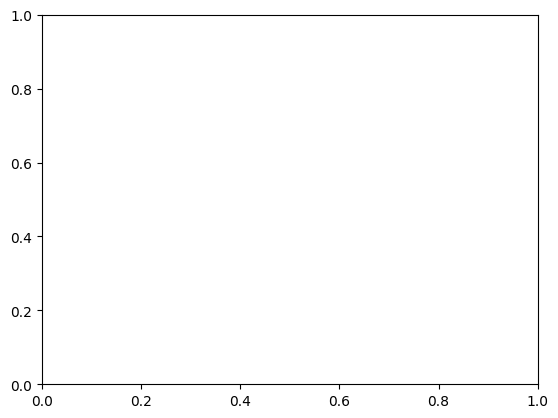

In [ ]:
# Visualize the initialization

import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots()

for _, row in particle_df.iterrows():
    x, y = row['CenterXY']
    r = row['Radius']

    particle = patches.Circle((x, y), r, edgecolor='dodgerblue', facecolor='none', linewidth=2)
    ax.add_patch(particle)

ax.set_aspect('equal', adjustable='box')

ax.set_xlim(0, grid_x)
ax.set_ylim(0, grid_y)

plt.show()

In [ ]:
# Theoretical values for comparison
# Comes from a super simplified Lifshitz-slyozov-Wagner (LSW mean radius law)
# <R>^3 - <R0>^3 = C*t where C is all of the extra terms simplified into a constant
# Return R_theory
import numpy as np

def R_avg_LSW(t,R0,C):
  R_theory = (R0**3 + C * t)**(1.0/3.0)
  return R_theory

#Remove ---
t_max = 10.0
dt = .1
t_array = np.arange(0, t_max + dt, dt)
R_theory = R_avg_LSW(t_array, R0=1.0, C=1.0) #Make sure to change R0 should be found from running dt_update 1st
#print(R_theory)




In [ ]:
#Ideally this will compare our simulation results with the theory results on a plot
#This requires a number average radius <r_sim> to be found each timestep
#INCLUDES 3 def. to make plots
#   <R> vs. time
#   <R>^3 vs. time
#   error

import matplotlib.pyplot as plt

def R_comparison(t, R_sim, R0, C):
  R_theory = R_avg_LSW(t, R0, C)

  plt.figure()
  plt.plot(t, R_sim, label="Simulation of <R(t)>")
  plt.plot(t, R_theory, label="LSW Theory")
  plt.xlabel("time")
  plt.ylabel("<R>")
  plt.legend()

#This will probably be easier to visualize as the slope should just be "C"
def R_cubic_comparison(t, R_sim, R0, C):
  R_theory = R_avg_LSW(t, R0, C)

  plt.figure()
  plt.plot(t, R_sim, label="Simulation of <R(t)>^3")
  plt.plot(t, R_theory, label="LSW Theory <R(t)>^3")
  plt.xlabel("time")
  plt.ylabel("<R>^3")
  plt.legend()

def R_error(t, R_sim, R0, C):
  R_theory = R_avg_LSW(t, R0, C)
  R_error = (R_sim - R_theory) / R_theory

  plt.figure()
  plt.plot(t, R_error)
  plt.xlabel("time")
  plt.ylabel("relative error")

In [ ]:
# Before use ------------
# Initialize dataframe
# For 1 time step , determine
# df : pd.DataFrame
#          - "name"       : Name of the particle # c
#          - 'num_atoms'  : current number of atoms in each particle
#          - 'Volume'     : current particle volume (will be overwritten)
#          - 'radius'     : current particle radius (will be overwritten)
# ------------------------
#NOT INCLUDED is a Temporary v_atom
def update_df(df, v_atom):
  df_new = df.copy()
  df_new = df_new[df_new["num_atoms"] > 0].reset_index(drop=True)
  #FORGOT TO CLEAN THE NN so Ill do it here
  if "NearestNeigbors" in df_new.columns:
    Not_removed = list(df_new["name"].values)
    New_list = []
    for q in df_new["NearestNeigbors"]:
        filtered_list = []
        for n in q:           # loop over each neighbor
          if n in Not_removed:   # keep only if the neighbor still exists
            filtered_list.append(n)

        New_list.append(filtered_list)

    df_new["NearestNeigbors"] = New_list
  df_new["Volume"] = df_new["num_atoms"] * v_atom
  df_new["radius"] = ((3.0 * df_new["Volume"]) / (4.0 * np.pi)) ** (1.0 / 3.0)
  R_avg = df_new["radius"].mean()
  num_particles = len(df_new)
  print(R_avg)

  return df_new, R_avg, num_particles

#R_sim = []
#R_sim.append(R_avg)

#v_atom = 1.0
#df, R_avgm num_particles = update_df(df, v_atom)



In [ ]:
import numpy as np
#The goal of this is to update the delta values by altering how many atoms
#have moved from each particle.
#Goal is to have array ex. [-1 -1 -1 0 0 +1 0 0 +2 0]
#TO USE NEED two arrays release_names and absorb_names
def delta_values(df, release_names, absorb_names, num_particles):

  delta_atoms = np.zeros(num_particles)

  for i in release_names:
    for j in range(len(df)):
      if df.loc[j, "name"] == i:
        delta_atoms[j] -= 1

  for i in absorb_names:
    for j in range(len(df)):
      if df.loc[j, "name"] == i:
        delta_atoms[j] += 1

  return delta_atoms

# ------------------------
#To use:
#num_particles =
#release_names = [1, 2, 5, 7, 10, 7]
#absorb_names =  [8, 8, 9, 9, 10, 10]
#delta_atoms = delta_values(df, release_names, absorb_names, num_particles)
# --> [0 -1 -1 0 0 -1 0 -2 2 2 1 0]





In [ ]:
#Before running this, there needs to be two def. One should create
#an array of release_probability, and one of absorb_probability
import numpy as np

def simple_monte_carlo(df, release_probability):
  names = df["name"].values
  num_particles = len(names) #Recalculate num_particles

#Random generate release
  release_idx = []

  for n in range(num_particles):
    prob = release_probability[n] #Use array for release prob scale of 0-1, ex. prob .4 if rand# < .4 it appends name to release
    rand = np.random.rand()
    if rand < prob:
      release_idx.append(n)

  n_events = len(release_idx)
  if n_events == 0:
    return [],[] #No events transpired in this time step

  release_names = [names[i] for i in release_idx]

  absorb_probability = absorb_probability_generator(df, release_idx)
  absorb_idx = []
  for r_ind in release_idx:
    probs = absorb_probability[r_ind] # pie chart over ALL particles
    a_idx = np.random.choice(num_particles, p=probs)
    absorb_idx.append(a_idx)

  absorb_names = [names[i] for i in absorb_idx]

  return release_names, absorb_names


In [ ]:
# I made a slight mistake with the weights. I chose the weights dependent on the number of atoms, but I think we said to do it based on radii
import numpy as np
def release_probability_generator (df): #def release_probability_generator (df, w1, w2): is probably much nicer
  atom_count = df["num_atoms"].values
  radii = df["radius"].values
  #------------
  # Weight functions to help better tune release will go here. Or we can include it in the inputs
  w1 = 1
  w2 = .025 #at 40 atoms --> release rate = 45%,     100 atoms --> 13.5 %
  #------------
  prob_eqn = w1 * np.exp(-w2 * radii)
  prob_eqn = np.minimum(1.0, np.maximum(0.0, prob_eqn)) # Added this so that w1 can be tuned >1 if needed although I don't know why
  release_probability = np.where(atom_count < 10, 1.0, prob_eqn) #Fix the list so it is 1.0 or leave it as is

  return release_probability

In [ ]:
# Apply weights and then normalize
import numpy as np
def absorb_probability_generator(df, release_names):
  radii = df["radius"].values
  neighbors = df["NearestNeigbors"].values
  names = df["name"].values

  r_min = radii.min()
  r_max = radii.max()

  absorb_w1 = .7        #Once again this is just a placeholder weight
  neighbor_weight = 2   #Once again this is just a placeholder weight

  if r_min == r_max:
    # all radii equal
    base_weights = np.ones_like(radii, dtype=float)
  else:
    radii_pos = radii - r_min + 1e-9
    base_weights = radii_pos ** absorb_w1


  name_to_index = {name: idx for idx, name in enumerate(names)}

  absorb_probability = {}
  for r_idx in release_names:
    weights = base_weights.copy()
    neighbor_list = neighbors[r_idx]

    if neighbor_list is not None:
      for k in neighbor_list:
        j = name_to_index.get(k)
        if j is not None:
          weights[j] *= neighbor_weight  # increase likelihood for neighbor

    total_w = weights.sum()
    probability = weights / total_w

    absorb_probability[r_idx] = probability

  return absorb_probability


In [ ]:
import pandas as pd

step = 0
max_steps = 10000
v_atom = 1.0
R_list = []        # store R_avg at each step
step_list = []     # store step numbers

#Example df that works with the code
df = pd.DataFrame({
    "name": ["A", "B", "C", "D", "E"],
    "num_atoms": [50, 20, 75, 8, 42],
    "radius": [3.0, 2.0, 4.0, 1.5, 2.5],
    "NearestNeigbors": [
        ["B", "C"],     # A neighbors: B, C
        ["A", "C", "E"],  # B neighbors: A, C, E
        ["A", "B"],     # C neighbors: A, B
        ["E"],        # D neighbors: E
        []          # E has no neighbors
    ]
})


while len(df) > 1 and step < max_steps:

  release_probability = release_probability_generator(df)
  #print(release_probability) #We can see this may be a bit too high
  release_names, absorb_names = simple_monte_carlo(df, release_probability)

  if len(release_names) == 0:
    print(f"No release events at step {step}.")

  deltas = delta_values(df, release_names, absorb_names,len(df))

  df["num_atoms"] = df["num_atoms"].values + deltas

  df, R_avg, num_particles = update_df(df,v_atom)
  print(df)
  #print(R_avg)
  R_list.append(R_avg)
  step_list.append(step)
  step += 1
#print(step_list)


1.9859665454551916
  name  num_atoms    radius NearestNeigbors  Volume
0    A       49.0  2.270052          [B, C]    49.0
1    B       19.0  1.655344       [A, C, E]    19.0
2    C       76.0  2.627695          [A, B]    76.0
3    D        7.0  1.186688             [E]     7.0
4    E       44.0  2.190053              []    44.0
1.9732121667458973
  name  num_atoms    radius NearestNeigbors  Volume
0    A       51.0  2.300526          [B, C]    51.0
1    B       18.0  1.625778       [A, C, E]    18.0
2    C       77.0  2.639170          [A, B]    77.0
3    D        6.0  1.127252             [E]     6.0
4    E       43.0  2.173335              []    43.0
1.9592366025990313
  name  num_atoms    radius NearestNeigbors  Volume
0    A       54.0  2.344778          [B, C]    54.0
1    B       17.0  1.595096       [A, C, E]    17.0
2    C       77.0  2.639170          [A, B]    77.0
3    D        5.0  1.060784             [E]     5.0
4    E       42.0  2.156355              []    42.0
1.94959

0. Initialize outside of loop

1. Determine release probability (def release_probabilities(df))
2. Plug output into def simple_monte_carlo(..) --> generates release_names and absorb_names in the form of 2 arrays

2a. Absorb is based on the id of the particle so we take the id of the particle that releases an atom and determine a pie chart for which particle will receive it. Do this for every released atom.

2b. The MonteCarlo will deternime the name of the particle that recieves atoms

3. Plug output of monteCarlo into def delta_values(..)

4. Apply changes to df

5. Run def update_df. Checks for any particles with no atoms left. Removes them

6. Run loop until 1 particle remains

SEE Above block for workflow. May require integration between parts.


In [ ]:
import matplotlib.pyplot as plt
t = np.array(step_list, dtype=float)
R_sim = np.array(R_list, dtype=float)

R0 = R_sim[0]

C = .1   # example value
R_comparison(t, R_sim, R0, C)
R_cubic_comparison(t, R_sim, R0, C)
R_error(t, R_sim, R0, C)

plt.show()


In [ ]:
import os
import csv
import numpy as np
import random
import math
import matplotlib.pyplot as plt
import argparse

plt.rcParams['axes.linewidth'] = 2
plt.style.use(r'C:\Users\Michael\OneDrive - Johns Hopkins\Documents\JHU\Python/weihs lab python.mplstyle')

#parser=argparse.ArgumentParser()

#--particles: number of particles in simulation
#--plotted_variale: can choose whether 'vol' (volume) or 'rad' (radius) is plotted against timestep
#--time: the amount of timesteps the simulation operates for. Usually somewhere around 10,000-60,000 depending on initial particle size.
#--save: chooses file type to save to 'png' 'pdf' etc.
#--radius: chooses the critical radius to simulate
#--Randomizer_seed: optional argument (all are optional but this is more) which provides a seed for random module
#If you want a progress bar, change the False inside the run3() command to True

# =============================================================================
# parser.add_argument('--particles', '-p')
# parser.add_argument('--plotted_variable', '-plot')
# parser.add_argument('--time', '-t')
# parser.add_argument('--save', '-s')
# parser.add_argument('--radius', '-r')
# parser.add_argument('--Randomizer_seed', '-seed')
#
# args=parser.parse_args([])
# =============================================================================

pi = math.pi
e = math.e

#critRad is mostly for testing purposes, no need to change it --radius does it for you.
critRad = 1.00
atomVol = 0.01
space = 3
atomMass = 0.01

#distMult is a multiplier I add to the gaussian distribution to get data that looks good
#It's not really necessary, but everything below critical radius goes to zero pretty much
#instantly so this means there are more values above it
distMult = 1.25

debug = 0
debug2 = 0
debug3 = 0

def eqn(rad):
    formula = e**(-1*(rad-1))
    return formula

def getCritVol(critRad):
    CritVolume = 4/3*pi*(critRad**3)
    return CritVolume

critVol = getCritVol(critRad)

def genGaussList(num, mu=critRad, sigma=1):
    numList = []
    for i in range(num):
        numList.append(random.gauss(mu, sigma))

    return numList

critVolSigma = critVol / 4

def genGaussVol(mu=critVol, sigma=critVolSigma):
    return random.gauss(mu, sigma)

class atom:
    def __init__(self, mass, vol, charge=0):
        self.mass = mass
        self.vol = vol
        self.charge=charge

    def getmass(self):
        return self.mass

    def getvol(self):
        return self.vol

    def getcharge(self):
        return self.charge

    def getradius(self):
        pass

class particle:

    def __init__(self, xPos, yPos, zPos=0,initAtoms=[], pid=None):
        self.volData=[]
        self.radData=[]
        self.atomlist = initAtoms
        self.x = xPos
        self.y = yPos
        self.z = zPos
        self.id = pid

    def getatomlist(self):
        return self.atomlist

    def addem(self, atom):
        self.atomlist.append(atom)

    def losem(self, index=0):
        lostAtom = self.atomlist.pop(index)
        return lostAtom

    def getVol(self):
        volSum = 0
        atomList = self.getatomlist()
        for atom in atomList:
            volSum += atom.getvol()
        self.vol = volSum
        return self.vol

    def getrad(self):
        vol=self.getVol()
        if debug2: print(vol)
        radius=(3/4/pi*vol)**(1/3)
        if debug2: print(radius)
        return radius

    def getnumAtoms(self):
        return len(self.getatomlist())

    def recordData(self):
        self.volData.append(self.getVol())
        self.radData.append(self.getrad())

    def getvolData(self):
        return self.volData

    def getradData(self):
        return self.radData

    def __str__(self):
        return f'Particle with volume of {round(self.getVol(),2)}, radius of {round(self.getrad(),3)}, and atom count of {round(self.getnumAtoms(),2)} at ({round(self.x, 2)},{round(self.y, 2)},{round(self.z, 2)})'

    def __repr__(self):
        return f'Particle with volume of {round(self.getVol(),2)}, radius of {round(self.getrad(),3)}, and atom count of {round(self.getnumAtoms(),2)} at ({round(self.x, 2)},{round(self.y, 2)},{round(self.z, 2)})'

class system:
    def __init__(self, particleList=[], criticalRadius=critRad, sysType='std', dimensions=''):
        self.lostpartList=[]
        self.partList = []
        self.log_data = []   # adding to log the data
        self.criticalRadius=criticalRadius
        self.dimensions=dimensions
        for particle in list(particleList):
            self.partList.append(particle)

    def copy(self, criticalRadius=critRad, sysType='std'):
        partList = list(self.getpartList())
        dims=str(self.getdimensions())
        newSys = system(partList, criticalRadius, sysType,dims)
        return newSys

    def getpartList(self):
        return self.partList

    def addPart(self, part):
        self.partList.append(part)

    def removefrompartList(self,particle):
        self.partList.remove(particle)

    def buildStdSystem(self, numParts, dimensions='10x10'):
        dimList = dimensions.split('x')
        self.dimList = list(dimList)
        self.numParts = numParts
        for i in range(len(dimList)):
            dimList[i] = int(dimList[i])
        while len(dimList) < space:
            dimList.append(0)

        dimStrList = []
        for i in range(len(dimList)):
            dimStrList.append(str(dimList[i]))

        self.dimensions = 'x'.join(dimStrList)

        gaussList = []

        for i in range(numParts):
            gaussList.append((genGaussVol()*distMult)//atomVol)

        for i in range(int(numParts)):
            randX = random.random()*dimList[0]
            randY = random.random()*dimList[1]
            randZ = random.random()*dimList[2]
            atomList = []

            for j in range(int(gaussList[i])):
                atomList.append(atom(atomMass, atomVol))

            self.addPart(particle(randX, randY, randZ, atomList, pid=i))

        if debug: print(self.partList)

    def getnumParts(self):
        return len(self.getpartList())

    def getdimensions(self):
        return self.dimensions

    def getdimList(self):
        return self.dimList

    def getlostpartList(self):
        return self.lostpartList

    def __str__(self):
        partList = self.getpartList()
        prtStr = f'{self.getdimensions()} system with {len(self.getpartList())} particles.\n'
        for particle in partList:
            prtStr += (str(particle) + '\n')

        return prtStr

    def __repr__(self):
        partList = self.getpartList()
        prtStr = f'{self.getdimensions()} system with {len(self.getpartList())} particles.\n'
        for particle in partList:
            prtStr += (str(particle) + '\n')

        return prtStr

    def log_timestep(self, timestep):                       # adding logging function for storing data
        for idx, part in enumerate(self.partList):
            radius = part.getrad()
            volume = part.getVol()
            num_atoms = part.getnumAtoms()
            self.log_data.append([
                timestep,
                part.id,      # original particle id
                radius,
                volume,
                num_atoms,
                part.x,
                part.y,
                part.z
            ])

    def iterate(self,criticalRadius):
        lostAtomList =[]
        partList=self.getpartList()
        templostpartList=[]
        for i in range(self.getnumParts()):
            part = partList[i]
            rad = part.getrad()
            if rad < criticalRadius:
                lostAtom=part.losem()
                lostAtomList.append(lostAtom)
            else:
                randNum = random.random()
                threshold = eqn(rad/criticalRadius)
                if randNum < threshold:
                    lostAtom=part.losem()
                    lostAtomList.append(lostAtom)

            part.recordData()

            if part.getnumAtoms() <=0:
                self.lostpartList.append(part)
                templostpartList.append(part)
            #part.recordData()

        for i in range(len(templostpartList)):
            self.removefrompartList(templostpartList[i])

        for i in range(len(lostAtomList)):
            randIndex=random.randint(0, self.getnumParts()-1)

            # random index is now based on the probability that the atom would go to a given particle
            # which is based on the particles' sizes

            # probability

            self.partList[randIndex].addem(lostAtomList[i])

    def iterateNtimes(self,N,rad=critRad, plot='rad',prt=True,save=False):
        xSpace=[]
        critLine=[]
        for i in range(N):
            self.iterate(rad)
            xSpace.append(i)

            if prt:
                print(f'{round((i+1)/N*100,2)}% complete')

            critLine.append(rad)

            # log
            self.log_timestep(i)

        initParts=int(self.getnumParts())

# =============================================================================
#         if plot=='vol':
#             combinedList = self.getpartList()+self.getlostpartList()
#             for i in range(len(combinedList)):
#                 tempxSpace = xSpace[:len(combinedList[i].getvolData())]
#                 plt.plot(tempxSpace, combinedList[i].getvolData())
#
#             plt.plot(xSpace,critLine, color="darkgrey", linestyle="--")
#             #plt.title(f'Particle Radius vs. Time {len(combinedList)}-Particle Plot')
#             plt.show()
#             #if save:
#             #    plt.savefig(f'CritRad_{rad}_{N}N_{len(combinedList)}_Particles_titled.{save}')
#             #    plt.close()
#
# =============================================================================
        #if plot=='rad':
            #combinedList = self.getpartList()+self.getlostpartList()
            #for i in range(len(combinedList)):
            #    tempxSpace = xSpace[:len(combinedList[i].getradData())]
            #    plt.plot(tempxSpace, combinedList[i].getradData())

            #plt.plot(xSpace,critLine, color="darkgrey", linestyle="--")
            #plt.title(f'Particle Radius vs. Time {len(combinedList)}-Particle Plot')
            #plt.show()
            #if save:
            #    plt.savefig(f'CritRad_{rad}_{N}N_{len(combinedList)}_Particles_titled.{save}')
            #    plt.close()


    def save_csv(self, filename="simulation_output.csv"):

        header = ["timestep", "particle_id", "radius", "volume", "num_atoms", "x", "y", "z"]
        with open(filename, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow(header)
            writer.writerows(self.log_data)


#
num_particles = 500              # number of particles
seeded = None           # random seed (None = unseeded)
num_iterations = 50000              # number of timesteps
critical_radius = 1.0               # critical radius
plotted_variable = 'rad'  # 'rad' or 'vol'
save = 'png'            # filetype to save ('png', 'pdf', etc.)
csv_save_folder = r"C:\Users\Michael\OneDrive - Johns Hopkins\Documents\JHU\Classes\Materials Modeling\Final Project\Simulation Results"


def run_simulation(parts, N,rad=critRad, plot='rad',prt=True,save=True):
    sys = system()
    sys.buildStdSystem(parts)
    sys.iterateNtimes(N,rad, plot,prt,save)

    csv_save_filename = f"simulation_{parts}parts_{critRad}criticalRadius_{N}steps.csv"
    csv_save_filepath = os.path.join(csv_save_folder, csv_save_filename)

    sys.save_csv(csv_save_filepath) # added to save data

if __name__ == '__main__':
    # Optional: set seed
    if seeded is not None:
        random.seed(seeded)

    run_simulation(num_particles, num_iterations, critical_radius, plotted_variable, False, save)

    print(f'Completed run with following parameters:\n'
          f'{num_particles} Particles\nseed={seeded}\nt={num_iterations}\n'
          f'Critical Radius of {critical_radius}\nPlotting {plotted_variable}\nSaved to {save}\n')

    #with open(f'CritRad_{critical_radius}_{num_iterations}N_{num_particles}_Particles.txt', 'w') as f:
    #    f.write(f'Completed run with following parameters:\n'
    #            f'{num_particles} Particles\nseed={seeded}\nt={num_iterations}\n'
    #            f'Critical Radius of {critical_radius}\nPlotting {plotted_variable}\nSaved to {save}')


